# Beyond Kemeny Medians: Consensus Ranking Distributions. Definition, Properties and Statistical Learning
This notebook contains all the experiments of the paper

In [1]:
from collections import Counter
from scipy.spatial.distance import cdist, pdist, squareform
import collections
import random
import seaborn as sns
import numpy as np
import itertools as it
import time
import scipy as sp
import pandas as pd
from  importlib import reload
from scipy.stats import kendalltau, spearmanr
import math 
from scipy.stats import ranksums

import matplotlib.pyplot as plt
import networkx as nx
from scipy.stats import kendalltau

import mallows_kendall as mk
import mallows_model as mm
import permutil as pu
import depth_aggregation as da
import partial_rankings as prank
from matplotlib.cm import get_cmap
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import matplotlib.cm as cm


# Auxliary functions

In [2]:
def plot_same_cluster_heatmap(M, title_str, ax):
    cmap = ListedColormap(["white", "green"])
    ax.imshow(M, cmap=cmap, interpolation="none")
    ax.set_title("Co-membership " + title_str)

def plot_COAST_graph(dfnodes, dfegds, n,name_str, title_str):
    # Create a directed graph where the nodes are at position x,y = (dist_to_med, dispersion), the label of a node is the iteration it was created
    # the iteration is an integer and should be shown as such, with no points
    
    G = nx.DiGraph()
    for idx, row in dfnodes.iterrows():
        # aux = str(int(row.iteration)) +' '+ str(round(row.hs_value,2 ))+' '+ str(int(row.num_samples))+' '+ str(int(row.dist_to_closest_center))
        #print(aux, row.hs_value)
        G.add_node(idx, pos=(row['dist_to_med'], row['dispersion']), iteration=row.iteration,  
                   dist_to_closest_center=row['dist_to_closest_center'] , num_samples=row.num_samples )#infor=aux,
    for idx, row in dfegds.iterrows():            
        from_node = dfnodes[(dfnodes['dist_to_med'] == row['from_dist_to_med']) & (dfnodes['dispersion'] == row['from_dispersion'])].index[0]
        to_node = dfnodes[(dfnodes['dist_to_med'] == row['to_dist_to_med']) & (dfnodes['dispersion'] == row['to_dispersion'])].index[0]
        G.add_edge(from_node, to_node)
    pos = nx.get_node_attributes(G, 'pos')
    labels = nx.get_node_attributes(G, 'iteration')
    size_dict = nx.get_node_attributes(G, 'num_samples')
    size = [10*size_dict[nod] for nod in G.nodes()] # 10 es a mano para justar a un tamano razonable
    node_colors = [ G.nodes[nod]['dist_to_closest_center']/n/(n-1)*2  for nod in G.nodes()]
    # node_colors = node_colors[1:]
    node_colors = node_colors / np.max(node_colors)
    # print(node_colors)
    fig, ax = plt.subplots(figsize=(5, 5))
    nx.draw(G, pos, with_labels=True, labels=labels,
            node_size=size, node_color=node_colors,
            font_size=10, font_weight='bold', arrows=True, ax=ax, cmap=plt.cm.coolwarm)
    ax.set_title(title_str, fontsize=16)
    ax.set_xlabel('Distance to its center')
    ax.set_ylabel('Dispersion')
    ax.grid(True)
    ax.set_axis_on()         
    ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True) 
    if name_str is not None:
        plt.savefig('img/COAST/COAST_graph_'+name_str, bbox_inches='tight')
    plt.show()
    
def plot_splitting_likelihood(df, k, title_str, name_str):
    sns.lineplot(data=df, x='Iteration', y='log likelihood')#add a vertical line at x=k
    plt.axvline(x=k, color='r', linestyle='--')
    plt.title(title_str)
    plt.savefig('img/COAST_likelihood_'+name_str, bbox_inches='tight')
    plt.show()

def plot_local_depths(dict_local_depths, title_str):
    arr = np.array(list(dict_local_depths.values()))
    labels = arr[:, 0]                   # etiqueta
    values = arr[:, 1:].astype(float)    # local depths

    plt.figure(figsize=(4, 4))

    color_map = {
        "corrupted": "green",
        "inlier": "blue",
        "outlier": "red",
    }

    legend_added = {k: False for k in color_map}

    for label, row in zip(labels[::-1], values[::-1]):
        key = label.lower()
        color = color_map.get(key, "black")

        if key in legend_added and not legend_added[key]:
            plt.plot(
                np.arange(1, 1 + len(row)),
                row,
                color=color,
                label=label,
            )
            legend_added[key] = True
        else:
            plt.plot(
                np.arange(1, 1 + len(row)),
                row,
                color=color,
            )

    plt.axvline(x=k, linestyle="--")  # no fijo color, como pedías en otros plots
    # plt.axhline(y=n*(n-1)/2, linestyle="--")

    plt.xlabel("Iteration")
    plt.ylabel("Local depth")
    print(title_str)
    plt.legend()
    

def plot_2_splits(df, col , save=True):
    df = df.copy()
    if col == 'Log likelihood':
        df = df[df.split_type == 'Approx']
    cols_experiment = ['n', 'k','mname','m','params']
    nk_pairs = df[cols_experiment].drop_duplicates()
    for _, row in nk_pairs.iterrows():
        mask = (df[cols_experiment] == row[cols_experiment]).all(axis=1)
        df_sub = df[mask]
        plt.figure(figsize=(4, 4))
        sns.lineplot(data=df_sub,x="Iteration",y=col,hue="Split type")
        #plt.axvline(x=row['k'], color='red', linestyle='--', label=f'k={row['k']}')
        plt.axvline(x=row['k'], color='red', linestyle='--', label=str(row['k']))
        if save: 
            name = get_plot_name(row['mname'], row['n'], row['k'], row['m'], col.replace(' ','_'), row['params'])
            if col=="avg_dist_true_centers" : plt.ylabel('Distance to centers')
            #elif col=="Distortion": plt.ylabel('Distortion')
            plt.tight_layout()
            plt.savefig(name, bbox_inches='tight')
        plt.show()

def distance_to_median(P):
    borda = da.bordaP(P)
    N = P.shape[0]*(P.shape[0]-1)//2
    return N - da.get_depth(P,borda), borda
    
def get_plot_name(mname, n, k, m,type_exper, params_value=.1): #only for MM, is phi
    params_value = str(params_value).replace(".", "_")
    name = f"img/COAST/{type_exper}_{mname}_n_{n}_k_{k}_m_{m}_param_{params_value}.pdf"
    return  name

def plot_path(P, dfpaths, sample, dist_name='k', central=None, ax=None, save_path=None, 
              borda=None, depth_type='distance',color_points=None,pre_title="",sample_matrices=None, ylab=None):
    res=[]
    if central is None: central = list(range(len(sample[0])))
    if ax is None: f, ax = plt.subplots(1,2, figsize=(16,4))
    res = []
    deepest = None # = [depth,dist]
    aux = color_points if color_points is not None else ['Sample']*len(sample)
    
    for perm,color in zip(sample,aux):
      #depth = len(sample)*pu.max_dist(n,dist_name) - pu.dist_to_sample(perm,P,dist_name=dist_name, sample=sample)
      depth = da.get_depth(P, perm, depth_type=depth_type,sample=sample,sample_matrices=sample_matrices)
      dist = pu.distance(perm,central,dist_name)
      res.append([depth,dist,color])
      if deepest is None or deepest[0] > depth:
        deepest = [depth,dist]
    df = pd.DataFrame(res,columns=['Depth', 'Distance to the center','color'])
    df = df.groupby(['Depth', 'Distance to the center','color']).size().reset_index(name='freq').reset_index(drop=True)
    #custom_palette = {"A": "red", "H": "green"}
    sns.scatterplot(data=df, x="Distance to the center", y="Depth",ax=ax, hue='color')#,palette=custom_palette)#,color=".2", hue='freq'
    ax.set_title(pre_title)#+"n="+str(n)+", m="+str(m)
    ax.set_xlabel(r'$d(\sigma, \sigma^*)$')
    if ylab is not None: 
        ax.set_ylabel(r'$D_{P^{('+str(ylab)+')}}(\sigma)$')
    else: 
        ax.set_ylabel(r'$\widehat D(\sigma)$')
    num_paths = dfpaths.num_path.nunique()
    for num_path in range(num_paths):
        aux = dfpaths[dfpaths.num_path==num_path]
        if len(aux)>0:
          ax.plot(aux.dist, aux.depth,'b-',alpha=.3)
          ax.plot(aux.iloc[-1].dist, aux.iloc[-1].depth, 'bx')
    if borda is not None: 
      #depth = len(sample)*pu.max_dist(n,dist_name) - pu.dist_to_sample(borda,P,dist_name=dist_name, sample=sample)
      depth = da.get_depth(P, borda, depth_type=depth_type,sample=sample,sample_matrices=sample_matrices)
      dist = pu.distance(borda,central,dist_name)
      ax.plot([dist],[depth],'ys',label='Borda')
      depth = da.get_depth(P, central, depth_type=depth_type,sample=sample)
      dist = pu.distance(central,central,dist_name)
      ax.plot([dist],[depth],'r*',label='Original median')
      ax.legend()
    ax.grid(True)
    if save_path is not None: plt.savefig(save_path, bbox_inches='tight')
    return deepest, ax

In [54]:

def copeland_ranking(P):
    wins = (P > 0.5).sum(axis=1)
    return np.argsort(np.argsort(-wins, kind='stable'))


def schulze_ranking(P):
    """
    Full Schulze method ranking from a pairwise preference matrix P,
    where P[i, j] = P{item i preferred to item j} (P[i,j] + P[j,i] = 1).

    Returns an array of item indices, best (rank 0) to worst.
    """
    n = P.shape[0]

    # direct victory strength: d[i,j] = P[i,j] if i beats j, else 0
    d = np.where(P > P.T, P, 0.0)

    # widest path (strongest path) via Floyd-Warshall-style relaxation
    strength = d.copy()
    for i in range(n):
        for j in range(n):
            if i == j:
                continue
            for k in range(n):
                if k == i or k == j:
                    continue
                strength[j, k] = max(strength[j, k], min(strength[j, i], strength[i, k]))

    # Schulze "beats" relation: i beats j iff strength[i,j] > strength[j,i]
    wins = np.array([
        sum(strength[i, j] > strength[j, i] for j in range(n) if j != i)
        for i in range(n)
    ])
    return np.argsort(np.argsort(-wins, kind='stable'))

class DistributionDistance:
    def __init__(self,  original_centers=None,original_phis=None, external_function_get_partition=None, max_n=10, log_dist=False):
        self.external_function_get_partition = external_function_get_partition
        self.max_n = max_n 
        self.original_centers = original_centers
        self.original_phis = original_phis
        self.original_probas = None
        self.n = len(self.original_centers[0])
        self.perms = np.array(list(it.permutations(range(self.n))))
        self.distri_dists = []
        self.clusters = []
        self.log_dist = log_dist
        if self.n <= self.max_n:
            self.explicit_original_distri()
            self.uniform = -np.log( math.factorial(self.n)) * np.ones(len(self.perms))
            #print("Uniform:", np.linalg.norm( self.uniform - self.original_probas ))
        self.all_probas = [self.original_probas]
        
    
    def explicit_original_distri(self):
        dists = np.array([
            [mk.distance(center, perm) for perm in self.perms]
            for center in self.original_centers
        ])
        if self.log_dist : 
            # log(probas_component) = dists * log(phi)
            log_probas_component = dists * np.log(self.original_phis)[:, None]
            # Zs son normalizadores -> usaremos su log
            log_Zs = np.log([
                mk.psi_mm(n=self.n, theta=mm.phi_to_theta(phi)) 
                for phi in self.original_phis
            ])
            # log probas = log numerator − log normalizer
            self.original_probas = log_probas_component - log_Zs[:, None]
            # Queremos la media SOBRE phis →
            # log(mean(exp(log p_i))) = logsumexp(log p_i) − log(m)
            self.original_probas = (
                scipy.special.logsumexp(self.original_probas, axis=0)
                - np.log(len(self.original_phis))
            )
        else:
            probas_component = self.original_phis[:, None].reshape(-1,1) ** dists
            Zs = np.array([
                mk.psi_mm(n=self.n, theta=mm.phi_to_theta(phi)) 
                for phi in self.original_phis
            ])
            self.original_probas  = probas_component / Zs.reshape(-1,1)
            self.original_probas = self.original_probas.mean(axis=0)
    
    def distance_to_original_distri(self, Ps, split_pairs=None):
        if self.n <= self.max_n: 
            check_sum = 0
            depth_probas, Ws, Zs, cluster = [], [] , [], []
            for P, pairs in zip(Ps, split_pairs):
                Z, cardinality = conditional_Z(P, pairs)
                Zs.append(Z)
                Ws.append( cardinality / math.factorial(self.n) )
            for perm in self.perms:
                P,Z,w, indi = self.get_partition(Ps,split_pairs, perm, Zs, Ws)
                if self.log_dist: 
                    depth_probas.append( np.log(w) + np.log(da.get_depth(P, perm, depth_type='distance'))  - np.log(Z)  )
                else:
                    depth_probas.append( w * da.get_depth(P, perm, depth_type='distance')  / Z )
                    cluster.append(indi)
            #print(np.std(depth_probas), "STD of depth_probas")
            #print()
            #     if indi == 1 : #cluster
            #         check_sum += da.get_depth(P, perm, depth_type='distance') 
            # if len(Zs)>=2:
            #     print(Zs[1], check_sum, "verify the partitioning ", Zs) 
            l2_dist = np.linalg.norm( np.array(depth_probas) - self.original_probas )
            #l1_dist = abs( np.array(depth_probas) - self.original_probas ).sum()
            self.distri_dists.append( l2_dist )
            self.clusters.append(np.array(cluster))
            self.all_probas.append( np.array(depth_probas) )
        else: self.distri_dists.append( -1 )  
    def plot(self):
        cols = np.array(self.clusters, dtype=float)
        if len(np.unique(cols)) > 1:
            cols_norm = (cols - cols.min()) / (cols.max() - cols.min())
        else:
            cols_norm = np.zeros_like(cols)
        cmap = cm.get_cmap("RdYlGn")   # mapa rojo → verde
        for (arr, c_norm) in zip(self.all_probas, cols_norm):
            color = cmap(c_norm)   # color único para este grupo
            plt.figure(figsize=(7, 3))
            plt.scatter(np.arange(len(arr)), arr - self.original_probas , color=color, s=20)
            plt.show()
    def plot_all_probas(self):
        plt.figure()
        for idx, sublist in enumerate(self.all_probas[1:]):
            x = range(len(sublist))
            y = sublist
            plt.scatter(x, y, label=f"lista {idx}")
        plt.legend()
        plt.show()
        plt.figure()
        for idx, sublist in enumerate(self.all_probas):
            x = range(len(sublist))
            y = sublist
            plt.scatter(x, y, label=f"lista {idx}")
        plt.legend()
        plt.show()
    
    def get_partition(self, Ps, split_pairs, perm, Zs, Ws):
            for i, (P, pairs ) in enumerate(zip(Ps, split_pairs)):
                consistent = True
                for j in range((len(pairs)-1)//2):
                    item1 = pairs[2*j+1]
                    item2 = pairs[2*j+2]
                    if perm[item1] > perm[item2]:
                        consistent = False
                        break
                if consistent:
                    return P, Zs[i], Ws[i] , i
            return None         

def get_partition(Ps, split_pairs, perm ): # DO NOT MOVE. same as the above, less params, external to the class 
        for i, (P, pairs ) in enumerate(zip(Ps, split_pairs)):
            consistent = is_consistent(pairs, perm )
            # consistent = True
            # for j in range((len(pairs)-1)//2):
            #     item1 = pairs[2*j+1]
            #     item2 = pairs[2*j+2]
            #     if perm[item1] > perm[item2]:
            #         consistent = False
            #         break
            if consistent:
                return P, pairs
        return None         

def is_consistent(pairs, perm):
    consistent = True
    for j in range((len(pairs)-1)//2):
        item1 = pairs[2*j+1]
        item2 = pairs[2*j+2]
        if perm[item1] > perm[item2]:
            consistent = False
            break
    return consistent

def conditional_Z(P, pairs):
    # used in log_likehood to compute the normalizing constant
    # returns the sum of all the permus that are consistent with pairs[1]<pairs[2], pairs[3]<pairs[4], ...
    # note that paris [0]=-1  
    n,_ = P.shape
    Paux = P.copy()
    tree_depth = (len(pairs)-1)//2
    for iterati in range(tree_depth): # pairs is initiallied with -1
        i,j = pairs[iterati*2+1], pairs[iterati*2+2]
        pr = np.full(n, np.nan)
        pr[i] = 0
        pr[j] = 1
        aux = prank.p_rank_to_mat(pr)
        Paux = Paux * aux
    cardinality = math.factorial(n) / (2 ** tree_depth) # number of permutations in this partition / leave
    conditionalZ = Paux.sum() * cardinality * (2 ** (tree_depth-1))  # sum of the depths of all permutations in this partition
    return conditionalZ, cardinality

def log_likehood(samples, Ps, Ps_len, split_pairs, split_type):
    # only for split_type = = Balanced size
    acum = 0 # log likelihood computed as sum of log depth of each sample under its component P
    # about the normalizing constant: this is easy when there is no restriction (see da.Z_depth_distri(P))
    # When the sum (the conditional) has to be done for a set of ermus that we can write as a 
    # top k ranking or a partial ranking we can also doit easily (becase the sum of the depths in this case is the product of the matrix pf the partual ranking and P)
    # to limit ourself to this cases (and since we are intereted in cases in which k<<n ), we build the tree with the constraint that if a pair (i,j) is chosen at a node, then these items
    #  cannot be choosen again to partition this subset. this does not affet in practice the tree
    # we could consier other restrictions. again, this ONLY affest the computetion of the normalizing constant on the likelihood. 
    if split_type != 'Approx': return np.nan
    n,_ = Ps[0].shape
    for sample, P, pairs in zip(samples, Ps, split_pairs):
        Z, cardinality = conditional_Z(P, pairs)
        norm_depths = np.array([  np.log( da.get_depth(P, perm,depth_type='distance'))   for perm in sample ])
        #slow = np.log(np.prod([   da.get_depth(P, perm,depth_type='distance')/Z   * cardinality/math.factorial(n)    for perm in sample ]))
        if n> 20: log_n_fact = math.lgamma(n + 1)
        else: log_n_fact = np.log(math.factorial(n))
        fast = len(sample) * (-log_n_fact +np.log(cardinality ) - np.log(Z) ) +  np.sum( norm_depths)
        #print(slow -  fast )
        acum += fast
    return acum
        
def compute_local_depths(samples, Ps, Ps_len, split_pairs, split_type, dict_local_depths):
    # save_local_depths: For the experiments of "extreme values". When True to store the depth of each perm in the sample along iterations
    for perm in dict_local_depths.keys():
        P,pairs = get_partition(Ps, split_pairs, perm) 
        if split_type == 'Exact':
            dict_local_depths[tuple(perm)].append(da.get_depth(P, perm,depth_type='distance')  ) #
        elif split_type == 'Approx':
            Z, cardinality =  conditional_Z(P, pairs)
            dict_local_depths[tuple(perm)].append(cardinality/math.factorial(n) * da.get_depth(P, perm,depth_type='distance') / Z ) #
        
def split_by_distortion(Ps, samples): # returns the pair and the node 
    best_dispersion = float('inf')
    # print("entering split_by_distortion")
    for k, (P,sample) in enumerate(zip(Ps, samples) ):
        n = P.shape[0]
        dispersion_0 = np.triu((1-P)*P).sum() 
        for i in range(n):
            for j in range(i+1, n): 
                mask = sample[:,i]<sample[:,j]
                sample_1 = sample[mask]
                sample_2 = sample[~mask]
                if len(sample_1)>0 and len(sample_2)>0: 
                    P1 = pu.sample_to_marg(sample_1)
                    P2 = pu.sample_to_marg(sample_2)
                    dispersion_1 = np.triu((1-P1)*P1).sum() 
                    dispersion_2 = np.triu((1-P2)*P2).sum() 
                    # from the total dispersion (which is equal for all, so we dont care) 
                    # we remove the dispersion of this partition and add the new dispersions
                    dispersion = -dispersion_0*len(sample) + ( len(sample_1) * dispersion_1 + len(sample_2) * dispersion_2) 
                    # print(i, j,  "-", len(sample)  , len(sample_1)  , len(sample_2) , dispersion )
                    if dispersion < best_dispersion:
                        best_dispersion = dispersion
                        best_k, best_i, best_j = k, i, j
    return [best_i, best_j], best_k

def split_by_max_hs(Ps, split_pairs): # returns the pair
    # returns the pair (i,j),  the index k and the value Ps[k][i,j]-0.5  such that Ps[k][i,j]-0.5 is minimum among all pairs and all Ps
    # we restrict to pairs (i,j) not in split_pairs[k], i.e., a pair cannot be used more than once to split a component (different leaves
    #  in the tree might use the same or different pairs ))
    min_hs_val = 999 # ins not rsly the max or the min, is the closeset to 0.5
    min_hs_pair = None
    indi = -1
    n = Ps[0].shape[0]

    random_order = np.random.permutation(n)
    # random.sample is to vitsit the Ps in random order
    for (k, P,pairs) in random.sample(list(zip(np.arange(len(Ps)), Ps, split_pairs)), len(Ps)):
        for ii in range(n):
            i = random_order[ii]
            if i not in pairs:
                for jj in range(i+1,n):
                    j = random_order[jj]
                    if j not in pairs:
                        hs_val = abs(P[i,j]-0.5)
                        if hs_val<min_hs_val:
                            min_hs_val = hs_val
                            min_hs_pair = [i,j]
                            indi = k
    if min_hs_val == 0.5:
        return None , None                   
    return min_hs_pair, indi

def compute_co_membership(sample, samples):
    # Create a mapping from permutation to ALL indices where it appears
    m = len(sample)
    index_map = {}
    # Build a list of indices for each unique permutation
    for i, p in enumerate(sample):
        t = tuple(p)
        if t not in index_map:
            index_map[t] = []
        index_map[t].append(i)
    M = np.zeros((m, m), dtype=int)
    for sub in samples:
        # Collect ALL indices for each permutation in this subsample
        all_indices = []
        for p in sub:
            t = tuple(p)
            if t in index_map:
                all_indices.extend(index_map[t])
        # Mark all pairs as co-clustered
        for i in all_indices:
            for j in all_indices:
                M[i, j] = 1
    return M

def mean_distortion(samples, Ps, Ps_len, split_pairs):
    res = []
    for sample, P, pairs in zip(samples, Ps, split_pairs):
        dispersion = np.triu((1-P)*P).sum() 
        res.append(dispersion * len(sample))
    return np.mean(res)


# The COAST algorithm

In [4]:

def coast(n, k,  sample, true_centers, split_type, max_itera=None, verbose=True,
          save_local_depths=False, dict_local_depths=None, 
          save_comembership=False, list_comembership=None, 
          save_distri_dist=False, obj_distri_dist=None): # aka splitting
    # split_type \in [Min distortion, Balanced size]
    # save_local_depths: For the experiments of "extreme values". When True to store the depth of each perm in the sample along iterations
    max_hs_val, best_pair = None , None
    likelihoods, local_depths = [], []
    samples, Ps, Ps_len, split_pairs = [], [], [], [] # this is the current distributio, which is being partitioned every iteration
    # split_pairs: list of items (i,j) used to split each component. 
    # to facilitate the computation of the likelihood (and ONLY for this reason!) we dont allow selecting an item more than once
    nodes = []
    edges = []
    max_itera = k + 6 if max_itera is None else max_itera
    m = len(sample)
    # sample_init = sample.copy()
    P = pu.sample_to_marg(sample).copy()
    # initialize the distribution with a single component
    Ps.append(P)
    Ps_len.append( 1 ) #weights of the components, i.e., ther proportion in the whole sample
    samples.append(sample.copy())
    split_pairs.append( [-1] ) 
    # initialize the descritive statistics of the component (distance to the median and dispersion, ...)
    dist_to_med, med = distance_to_median(P)
    dispersion = np.triu((1-P)*P).sum() 
    components_ed_med = [dist_to_med]
    components_ed_pair = [dispersion]
    
    nodes.append([0, dist_to_med, dispersion, len(sample),0, min([mk.distance(c,med) for c in true_centers]) ])
    start = time.time()
    # OJO: this is done also at the end of the loop, but we need it here to have the initial likelihood
    avg_dist_true_centers = np.mean([min([mk.distance(c,da.bordaP(P)) for c in true_centers]) for P in Ps])
    likelihoods.append([1, k , log_likehood(samples, Ps, Ps_len, split_pairs, split_type), mean_distortion(samples, Ps, Ps_len, split_pairs), split_type , n, avg_dist_true_centers])
    if save_local_depths :# and split_type == 'Approx': # they are stored in dict_local_depths
        compute_local_depths(samples, Ps, Ps_len, split_pairs, split_type, dict_local_depths)
    if save_distri_dist and split_type == 'Approx':
        obj_distri_dist.distance_to_original_distri(Ps, split_pairs)

    for itera in range(2,max_itera+1): #itera is also the number of partitions found 
        if split_type == 'Approx':
            best_pair, indi = split_by_max_hs(Ps, split_pairs)
        elif split_type == 'Exact':
            best_pair, indi = split_by_distortion(Ps, samples)
        else: Exception("split type error")
        if best_pair is None:
            print("No more pairs to split, stopping at iteration ", itera)
            break
        # pop the component to be splitted
        P = Ps.pop(indi)
        _ = Ps_len.pop(indi)
        sample_aux = samples.pop(indi)
        split_pairs_branch = split_pairs.pop(indi)
        # print(split_pairs_branch, max_hs_pair)
        # compute the two new components (split)
        x = components_ed_med.pop(indi)
        y = components_ed_pair.pop(indi)
        # split sample
        mask = sample_aux[:,best_pair[0]]<sample_aux[:,best_pair[1]]
        sample_1 = sample_aux[mask]
        sample_2 = sample_aux[~mask]
        P1 = pu.sample_to_marg(sample_1)
        P2 = pu.sample_to_marg(sample_2)
        # compute the statistics of the new components
        dispersion_1 = np.triu((1-P1)*P1).sum() 
        dist_to_med_1, med_1 = distance_to_median(P1)
        dispersion_2 = np.triu((1-P2)*P2).sum() 
        dist_to_med_2, med_2 = distance_to_median(P2)
        dist_to_closest_center_1 = min([mk.distance(c,med_1) for c in true_centers])
        dist_to_closest_center_2 = min([mk.distance(c,med_2) for c in true_centers])
        # add the new components to the distribution
        Ps.append(P1)
        Ps.append(P2)
        Ps_len.append(len(sample_1)/m )
        Ps_len.append(len(sample_2)/m )    
        samples.append(sample_1)
        samples.append(sample_2)
        split_pairs.append( split_pairs_branch + [best_pair[0],best_pair[1]] ) 
        split_pairs.append( split_pairs_branch + [best_pair[1],best_pair[0]] ) 
        # update aux structures
        components_ed_med.append(dist_to_med_1)
        components_ed_med.append(dist_to_med_2)
        components_ed_pair.append(dispersion_1)
        components_ed_pair.append(dispersion_2)
        edges.append([x,y,dist_to_med_1,dispersion_1 ])
        edges.append([x,y,dist_to_med_2,dispersion_2 ])
        nodes.append([itera, dist_to_med_1, dispersion_1, len(sample_1), med_1, dist_to_closest_center_1])
        nodes.append([itera, dist_to_med_2, dispersion_2, len(sample_2), med_2, dist_to_closest_center_2])
        if save_comembership and (itera==k or itera==max_itera): 
            list_comembership.append( compute_co_membership(sample, samples) )
        if save_local_depths :# and split_type == 'Approx': # they are stored in dict_local_depths
            compute_local_depths(samples, Ps, Ps_len, split_pairs, split_type, dict_local_depths)
        if save_distri_dist and split_type == 'Approx':
            obj_distri_dist.distance_to_original_distri(Ps, split_pairs)


        avg_dist_true_centers = np.mean([min([mk.distance(c,da.bordaP(P)) for c in true_centers]) for P in Ps])    
        likelihoods.append([itera, k , log_likehood(samples, Ps, Ps_len, split_pairs, split_type), mean_distortion(samples, Ps, Ps_len, split_pairs), split_type , n, avg_dist_true_centers])    
        # verify
        # for sample,P in zip(samples, Ps):
        #     # print(len(sample), "len sample, assert que todas son compatibles con su P")
        #     for perm in sample:
        #         assert( da.get_depth(P, perm,depth_type='prod') != 0 )
            
    
    mytime = time.time() - start
    if verbose: 
        print("Time", n, k, split_type, mytime)
    dfnodes = pd.DataFrame(nodes, columns=['iteration', 'dist_to_med', 'dispersion', 'num_samples', 'median', 'dist_to_closest_center'])
    dfedges = pd.DataFrame(edges, columns=['from_dist_to_med', 'from_dispersion', 'to_dist_to_med', 'to_dispersion'])
    dfinfo = pd.DataFrame(likelihoods,columns=['Iteration', 'k','Log likelihood', 'Distortion', 'Split type' , 'n', 'avg_dist_true_centers'])
    if split_type == 'Approx' and save_distri_dist:
        dfinfo['Distance to original distribution'] = obj_distri_dist.distri_dists
    return dfinfo, dfnodes, dfedges, Ps, Ps_len, samples, split_pairs


# COAST on synthetic data

In [55]:
reload(pu)
m = 50 # number of samples per component
repes = 5
mnames = ['mm_ken', 'pl'] #'pl',
phis = [.1, .3] #.3
ns = [10, 50, 100, 150] #150
ks = [4, 8]#8

split_types = ['Approx']#,'Exact'
list_aggregation= [] 
df = pd.DataFrame()  
for n in ns:
    for k in ks:
        for split_type in split_types: 
            for mname in mnames:
                if mname == 'mm_ken' :
                    params_list = phis
                elif mname == 'pl':
                    params_list = [ np.array([np.exp(n-i) for i in range(n)]) ] #inlcude as list to be compatible
                for params in params_list:
                    for repe in range(repes):
                        centers = [np.random.permutation(range(n)) for _ in range(k)]
                        sample = np.concatenate([pu.sample(n,m,  model=mname, params=params, central=centers[i] ) for i in range(k)])
                        #obj_distri_dist = DistributionDistance(centers, np.array([phi]*k))
                        dfinfo, dfnodes, dfedges, Ps, Ps_len, samples, split_pairs = coast(n,k, sample, centers, split_type, max_itera=k+4)
                        dfinfo['mname'] = mname
                        dfinfo['m'] = m
                        dfinfo['split_type'] = split_type
                        dfinfo['params'] = params if mname=='mm_ken' else 0
                        df = pd.concat([df,dfinfo])
                        for P in Ps: 
                            list_aggregation.append([n,k,split_type, mname, dfinfo.params.values[0], mk.distance(mk.median(P), copeland_ranking(P)), mk.distance(mk.median(P), schulze_ranking(P)) ])
                            
                        

#plot_2_splits(df, 'Distortion')
#plot_2_splits(df, 'avg_dist_true_centers')
###plot_2_splits(df, 'Log likelihood')

Time 10 4 Approx 0.0907130241394043
Time 10 4 Approx 0.08299994468688965
Time 10 4 Approx 0.08289694786071777
Time 10 4 Approx 0.07332396507263184
Time 10 4 Approx 0.07914400100708008
Time 10 4 Approx 0.08145809173583984
Time 10 4 Approx 0.07884407043457031
Time 10 4 Approx 0.06951212882995605
Time 10 4 Approx 0.07185673713684082
Time 10 4 Approx 0.07903504371643066
Time 10 4 Approx 0.08015704154968262
Time 10 4 Approx 0.07094120979309082
Time 10 4 Approx 0.09514999389648438
Time 10 4 Approx 0.07329106330871582
Time 10 4 Approx 0.12220120429992676
Time 10 8 Approx 0.2570321559906006
Time 10 8 Approx 0.23424100875854492
Time 10 8 Approx 0.20766115188598633
Time 10 8 Approx 0.23669910430908203
Time 10 8 Approx 0.1931910514831543
Time 10 8 Approx 0.21236300468444824
Time 10 8 Approx 0.20041823387145996
Time 10 8 Approx 0.20462512969970703
Time 10 8 Approx 0.20795893669128418
Time 10 8 Approx 0.29685187339782715
Time 10 8 Approx 0.22802996635437012
Time 10 8 Approx 0.2060229778289795
Time 

In [66]:
df_aggegation = pd.DataFrame(list_aggregation, columns=['n','k','split_type', 'mname', 'params', 'Error Copeland', 'Error Schulze'])
df_aggegation.groupby(['n','k'])[['Error Copeland', 'Error Schulze']].mean()

Error Copeland  Error Schulze
n   k                               
10  4        0.475000       0.450000
    8        1.116667       1.022222
50  4        1.133333       1.141667
    8        0.905556       0.900000
100 4        3.291667       3.275000
    8        1.950000       1.911111
150 4        4.108333       4.100000
    8        3.072222       3.027778

In [70]:
(df_aggegation==0).sum(), len(df_aggegation)

(n                   0
 k                   0
 split_type          0
 mname               0
 params            400
 Error Copeland    778
 Error Schulze     780
 dtype: int64,
 1200)

# Smoothing
In this experiments, we compute the L2 distance between the original distribution and the smothed distribution at each iteration. 
For the smoothing, we use the depths-based-distribution. 

Time 8 4 Approx 8.81847620010376
No more pairs to split, stopping at iteration  8
Time 8 4 Approx 7.578591823577881
Time 8 4 Approx 8.683281183242798
Time 8 4 Approx 8.645510911941528
Time 8 4 Approx 8.45767593383789


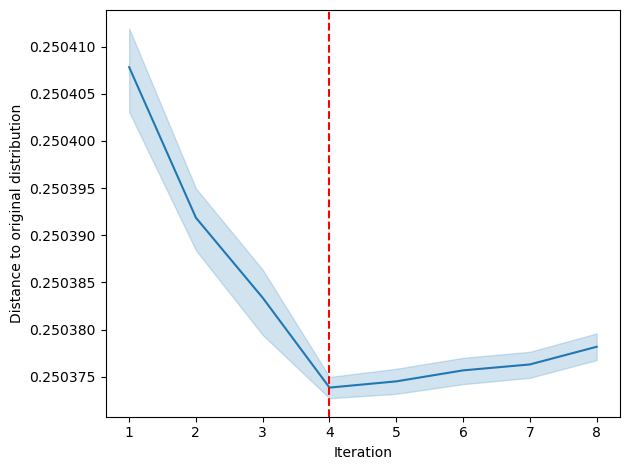

In [6]:
reload(pu)
# n = 100
# k = 32
m = 50 # number of samples per component
repes = 5
mname = 'mm_ken'
phi = 00.1
df = pd.DataFrame()  

for n in [8]:# , 50, 100, 150]
    for k in [4]:
        for split_type in ['Approx']: #, 'Min distorsion'
            params = phi
            for repe in range(repes):
                centers = [np.random.permutation(range(n)) for _ in range(k)]
                sample = np.concatenate([pu.sample(n,m,  model=mname, params=params, central=centers[i] ) for i in range(k)])
                obj_distri_dist = DistributionDistance(centers, np.array([phi]*k) )
                dfinfo, dfnodes, dfedges, Ps, Ps_len, samples, split_pairs = coast(n,k, sample, centers, split_type, max_itera=k+4,
                                                                                   save_distri_dist=True, obj_distri_dist=obj_distri_dist)
                df = pd.concat([df,dfinfo])
sns.lineplot(data=df, x='Iteration', y='Distance to original distribution')#add a vertical line at x=k
plt.axvline(x=k, color='r', linestyle='--')
plt.tight_layout()
#plt.savefig('img/splitting/smoothing_'+str(n)+'.pdf', bbox_inches='tight')


# Clustering
the correct clustering in the dataset is recovered, even when the components are very uniform

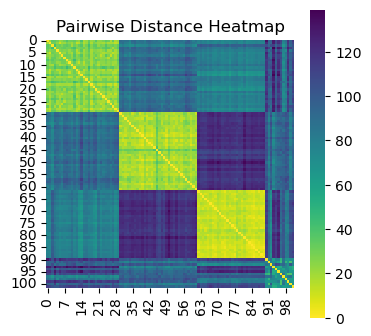

Time 20 4 Approx 0.11557197570800781
img/COAST/co_membership_out_Approx__mm_ken_n_20_k_4_m_10_param_0_3.pdf


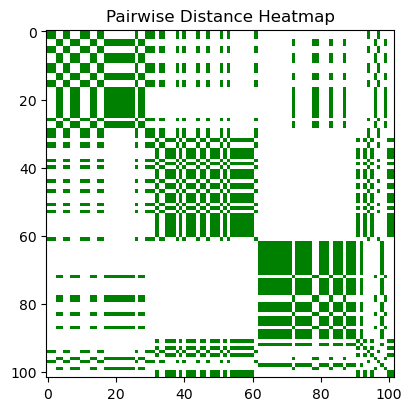

In [7]:
ns = [20]
ks = [4]
split_types = ['Approx']#, 'Exact'
mnames = ['mm_ken' ] #, 'pl'
phis = [0.3]#, 0.5, 0.7
m = 10 # number of samples per component
len_rands = 0 # number of random permus not belonging to any component
repes = 1
df = pd.DataFrame()  
for n in ns:
    for k in ks:
        for mname in mnames:
            if mname == 'mm_ken' :
                params_list = phis
            elif mname == 'pl':
                params_list = [ np.array([np.exp(n-i) for i in range(n)]) ] #inlcude as list to be compatible
            for params in params_list:
                centers = [np.random.permutation(range(n)) for _ in range(k)]
                #print("Dist at unif",n*(n-1)//4, " Distances: " , pdist(centers, metric=mk.distance) ) 
                sample = np.concatenate([pu.sample(n,int(random.uniform(5, 50)),  model=mname, params=random.uniform(0.05, 0.95), central=centers[i] ) for i in range(k)])
                # plot distance matrix
                dist_condensed = pdist(sample, metric=mk.distance)
                dist_matrix = squareform(dist_condensed)
                plt.figure(figsize=(4,4))
                sns.heatmap(dist_matrix, cmap='viridis_r', square=True)
                plt.title("Pairwise Distance Heatmap")
                if mname == 'pl': params_str=0
                else: params_str=params
                name_str = get_plot_name(mname, n, k, m,"co_membership_in_", params_str)
                plt.savefig(name_str, bbox_inches='tight')
                plt.show()
            
                for split_type in split_types:
                    list_comembership = []    
                    dfinfo, dfnodes, dfedges, Ps, Ps_len, samples, split_pairs = coast(n,k, sample.copy(), centers, split_type, max_itera=k+4,
                                                                                    save_comembership=True, list_comembership=list_comembership)
                    #fig, axes = plt.subplots(1, 2, figsize=(8,3), constrained_layout=True)
                    fig, ax = plt.subplots(figsize=(4,4), constrained_layout=True)
                    plot_same_cluster_heatmap(list_comembership[0], "", ax=ax) #iteration k
                    #plot_same_cluster_heatmap(list_comembership[1], "", ax=axes[1]) #iteration last
                    if mname == 'pl': params_str=0
                    else: params_str=params
                    name_str = get_plot_name(mname, n, k, m,"co_membership_out_"+split_type.replace(" ", "_")+'_', params_str)
                    print(name_str)
                    plt.title("Pairwise Distance Heatmap")
                    if split_type == 'Exact': 
                        plt.savefig(name_str, bbox_inches='tight')
                    plt.show()
                    
 


# Local depths for anomaly detection
In this experiment we compute the local depths of a test-sample in every iteration. The test-sample has k data points drawn from the k components of the mixture (original distribution) and k random permutations

Time 20 8 Approx 0.8771567344665527

img/COAST/local_depth_Approx__pl_n_20_k_8_m_20_param_0.pdf


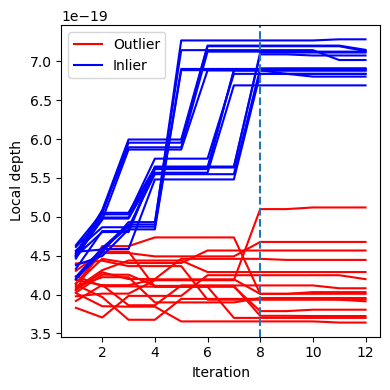

Time 20 8 Exact 0.8806350231170654

img/COAST/local_depth_Exact__pl_n_20_k_8_m_20_param_0.pdf


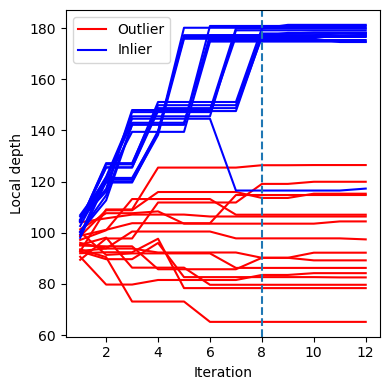

Time 20 8 Approx 0.8710038661956787

img/COAST/local_depth_Approx__mm_ken_n_20_k_8_m_20_param_0_3.pdf


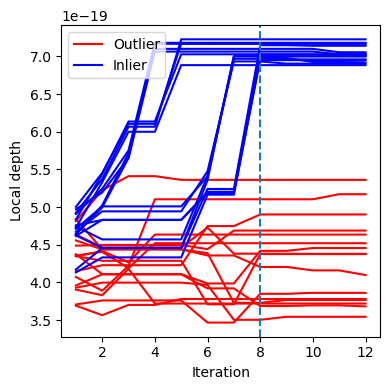

Time 20 8 Exact 0.9134130477905273

img/COAST/local_depth_Exact__mm_ken_n_20_k_8_m_20_param_0_3.pdf


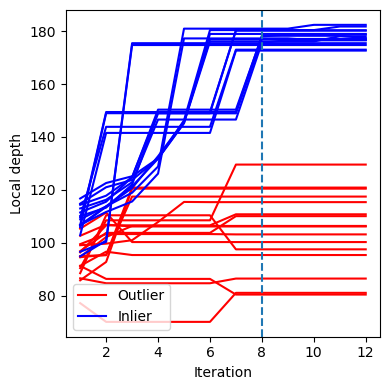

In [8]:


ns = [20]
ks = [8]
split_types = ['Approx', 'Exact']#
mnames = ['pl', 'mm_ken' ] #
phis = [0.3]
m = 20 # number of samples per component
m_test = 2
len_rands = 0 # number of random permus not belonging to any component
repes = 1
# split_type  = 'Min distorsion'#'Approx'#
df = pd.DataFrame()  
pvals = []
for n in ns:
    for k in ks:
        for mname in mnames:
            if mname == 'mm_ken' :
                params_list = phis
            elif mname == 'pl':
                params_list = [ np.array([np.exp(n-i) for i in range(n)]) ] #inlcude as list to be compatible
            for params in params_list:
                centers = [np.random.permutation(range(n)) for _ in range(k)]
                #print("Dist at unif",n*(n-1)//4, " Distances: " , pdist(centers, metric=mk.distance) ) 
                sample = np.concatenate([pu.sample(n,m,  model=mname, params=params, central=centers[i] ) for i in range(k)])
                # plot distance matrix
                dist_condensed = pdist(sample, metric=mk.distance)
                dist_matrix = squareform(dist_condensed)
                # plt.figure(figsize=(4,4))
                # sns.heatmap(dist_matrix, cmap='viridis_r', square=True)
                # plt.title("Pairwise Distance Heatmap")
                # plt.show()
                pvals = []
                for split_type in split_types:
                    inliers = np.concatenate([pu.sample(n,m_test,  model=mname, params=params, central=centers[i] ) for i in range(k)])
                    outliers = np.array([np.random.permutation(range(n)) for _ in range(m_test*len(centers))]) 
                    #corrupted = np.concatenate([pu.sample(n,m_test,  model=mname, params=params, central=centers[i][::-1] ) for i in range(k)])
                    test_sample = np.concatenate( [inliers, outliers ]) # concat k random permus
                    dict_local_depths = {}
                    for perm in inliers:
                        dict_local_depths[tuple(perm)] = ['Inlier']
                    for perm in outliers:
                        dict_local_depths[tuple(perm)] = ['Outlier']
                    #for perm in corrupted:dict_local_depths[tuple(perm)] = ['Corrupted']
                    list_comembership = []    
                    dfinfo, dfnodes, dfedges, Ps, Ps_len, samples, split_pairs = coast(n,k, sample.copy(), centers, split_type, max_itera=k+4,
                                                                                    save_local_depths=True, dict_local_depths=dict_local_depths, 
                                                                                    save_comembership=True, list_comembership=list_comembership)
                    #fig, axes = plt.subplots(1, 2, figsize=(8,3), constrained_layout=True)
                    #plot_same_cluster_heatmap(list_comembership[0], "", ax=axes[0]) #iteration k
                    #plot_same_cluster_heatmap(list_comembership[1], "", ax=axes[1]) #iteration last
                    #plt.show()
                    plot_local_depths(dict_local_depths, "")
                    plt.tight_layout()
                    if mname == 'pl': params_str=0
                    else: params_str=params
                    name_str = get_plot_name(mname, n, k, m,"local_depth_"+split_type.replace(" ", "_")+'_', params_str)
                    print(name_str)
                    plt.savefig(name_str, bbox_inches='tight')
                    plt.show()
#plot_splitting_graph(dfnodes, dfedges, n, "", "") # only the last repetition
 


# Local median

## Local median estimation in CRD

The Pc are SST iff the secuence of pairs (i,i) to condition is choosen in a very specific way. This gives rise to the depth trimmed regions

the resultsing Pc are almost-SST: a local search by depth arrives to the $\sigma\in C$ that is the local median



Dist at unif 612  Distances:  [604. 596. 630. 580. 522. 598.]
Time 50 4 Approx 0.12675786018371582


,Iteration,k,Log likelihood,Distortion,Split type,n,avg_dist_true_centers
0,1,4,-29656.549116,48046.6300,Approx,50,351.000000
1,2,4,-29630.007876,18014.6100,Approx,50,277.000000
2,3,4,-29612.707505,8884.0300,Approx,50,103.666667
3,4,4,-29612.635867,6634.9525,Approx,50,86.750000


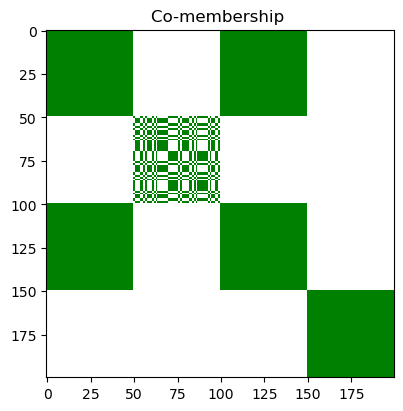

In [9]:
reload(da) 
# n=30, phi=0.8 esta bien
# n=50, phi=0.89 esta bien
n = 50
k = 4
split_type = 'Approx'# ['Approx']#
mname = 'mm_ken'
phi = 0.7
m = 50 # number of samples per component
#repes = 1
df = pd.DataFrame()  

params = None
centers = [np.random.permutation(range(n)) for _ in range(k-1)]
centers.append( np.array(list(range(n))) ) # add the identity as a center
print("Dist at unif",n*(n-1)//4, " Distances: " , pdist(centers, metric=mk.distance) ) 
sample = np.concatenate([pu.sample(n,m,  model=mname, params=phi, central=centers[i] ) for i in range(k)])
list_comembership =[]
dfinfo, dfnodes, dfedges, Ps, Ps_len, samples, split_pairs = coast(n,k, sample.copy(), centers, split_type, max_itera=k, 
                                                                   save_comembership=True, list_comembership=list_comembership)
                    
#fig, ax = plt.subplots(figsize=(8, 3), constrained_layout=True)
#plot_same_cluster_heatmap(list_comembership[0], "", ax=ax) #iteration k
fig, ax = plt.subplots(figsize=(4,4), constrained_layout=True)
plot_same_cluster_heatmap(list_comembership[0], "", ax=ax) #iteration k
name_str = get_plot_name(mname, n, k, m,"DAggre_co_memb", params_str)
plt.savefig(name_str, bbox_inches='tight')
                                

df = pd.concat([df,dfinfo])

df

Borda is the true center? False
Borda and DA medians are in P? True True


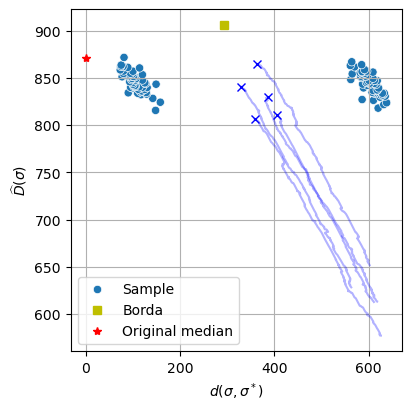

Borda is the true center? False
Borda and DA medians are in P? True True


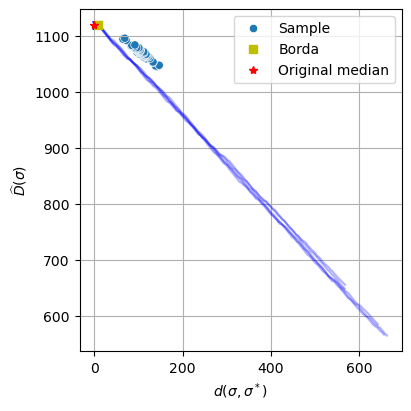

Borda is the true center? False
Borda and DA medians are in P? True True


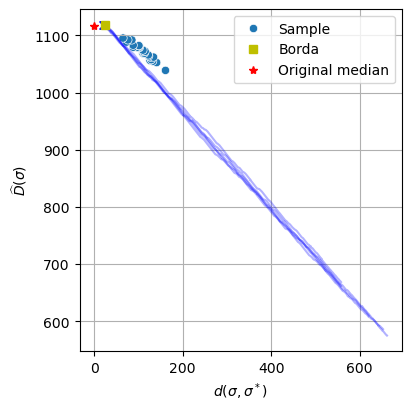

Borda is the true center? False
Borda and DA medians are in P? True True


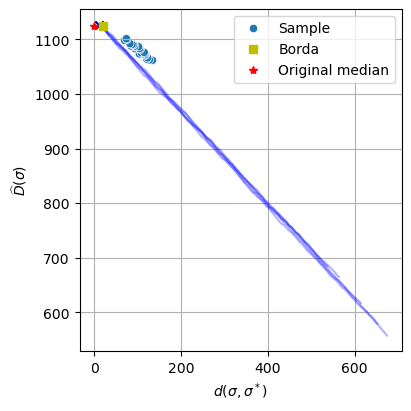

In [10]:
res = []              
depth_type = 'distance'
num_paths = 5 

for indexP, (sample,P, pairs) in enumerate(zip(samples,Ps, split_pairs)):
    res = []
    center = centers[np.argmin([mk.distance(c,da.bordaP(P)) for c in centers])]
    print("Borda is the true center?", 0 == mk.distance(da.bordaP(P), center))
    for repe in range(num_paths):
        found = False
        while not found :
            perm = np.random.permutation(range(n))
            found = is_consistent(pairs, perm) 
        _,_,nodes = da.depth_aggregation(P, initial_permu=perm, test_mode=True, depth_type=depth_type, stochastic_accept=0)
        for node  in nodes:
            res.append([node[1], mk.distance(node[0],center), repe, perm, depth_type, is_consistent(pairs, node[0]) ])
    
    dfpaths = pd.DataFrame(res, columns=['depth', 'dist', 'num_path','perm','depth_type','consistent_with_P'])
    #assert(0== len(dfpaths[~dfpaths.consistent_with_P]))# check all permus in the paths are consistent with P (only is true when worse permus are not allowed, i.e. stochastic_accept!=0))
    print("Borda and DA medians are in P?", is_consistent(pairs, da.bordaP(P)), is_consistent(pairs, nodes[-1][0]) )
    save_path='img/COAST/DAggre_n'+str(n)+'_phi'+str(round(phi,2)).replace('.','_')+'_'+str(indexP)+'.pdf'
    fig, ax = plt.subplots(figsize=(4,4), constrained_layout=True)
    plot_path(P, dfpaths[dfpaths.depth_type==depth_type], sample, dist_name='k', central=center, ax=ax, 
            save_path=save_path, borda=da.bordaP(P), depth_type=depth_type,color_points=None)
    plt.show()  

# Local and Global depths

<Figure size 400x400 with 0 Axes>

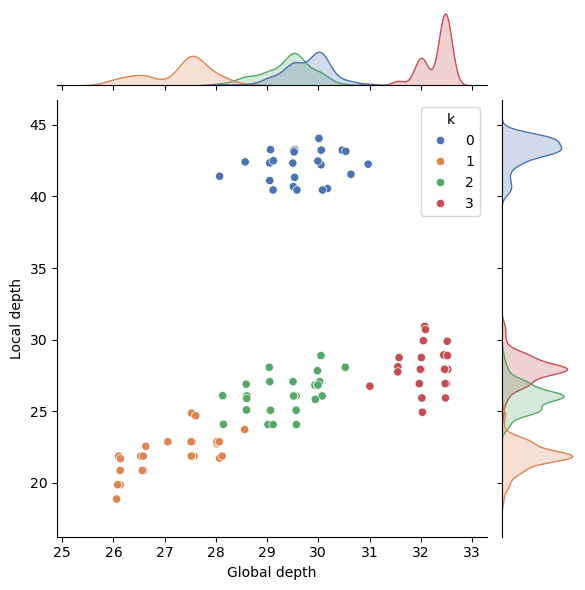

<Figure size 400x400 with 0 Axes>

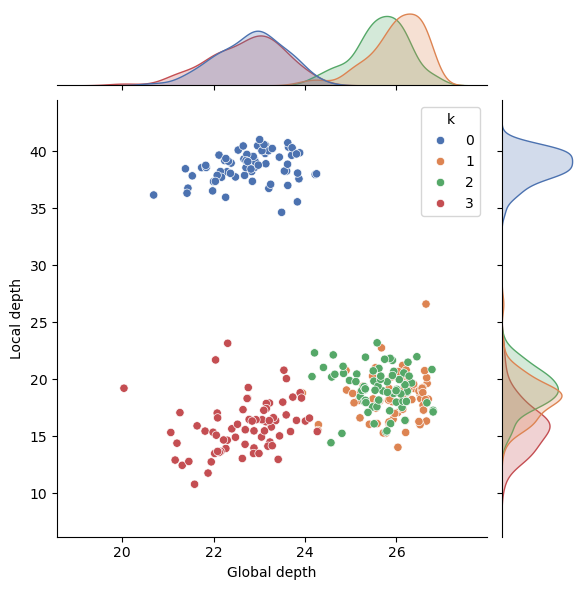

In [11]:
# test df
reload(da)
ns = [10]
ks = [4]#, 8
#split_types = ['Exact','Approx']#, 'Exact', 'Approx'
mnames = ['mm_ken', 'pl'] #pl
phis = [.1]#, .3, .5
m = 100 # number of samples per component
len_rands = 0 # number of random permus not belonging to any component
repes = 1
# split_type  = 'Min distorsion'#'Approx'#
df = pd.DataFrame()  
len_samples = 300 # number of samples generated using the MCMC
sampling_from_depth = False # we can sample explicitly for the distributions or (2) from the depths using the MCMC

for n in ns:
    for k in ks:
        for mname in mnames:
            if mname == 'mm_ken' :
                params_list = phis
            elif mname == 'pl':
                params_list = [ np.array([np.exp(n-i) for i in range(n)]) ] #inlcude as list to be compatible
            for params in params_list:
                res = []
                centers = [np.arange(n)] + [np.random.permutation(range(n)) for _ in range(k-1)]
                # TRAIN sample: hese samples come from the distribution
                samples_k = [pu.sample(n,m,  model=mname, params=params, central=centers[i] ) for i in range(k)]
                sample = np.concatenate(samples_k)
                Pglobal = pu.sample_to_marg(sample=sample)
                Plocal =  pu.sample_to_marg(sample=samples_k[0] )  
                # TEST sample: hese samples come from the distribution
                for i in range(k):
                    for perm  in pu.sample(n,len_samples//k,  model=mname, params=params, central=centers[i] ):
                        res.append(['Exact', perm, i, da.get_depth(Pglobal,perm), da.get_depth(Plocal,perm) ])
                #TeST sample 2: these samples come from the depth!
              #  test_global_MCMC = [da.MCMC(Pglobal, len_mcmc=1, burn_out=100)[1][0]     for _ in range(len_samples-len_samples//k)]
              #  test_local_MCMC = [da.MCMC(Plocal, len_mcmc=1, burn_out=100)[1][0]     for _ in range(len_samples//k)]
              #  for perm in test_local_MCMC:
              #       res.append(['MCMC', perm, 0, da.get_depth(Pglobal,perm), da.get_depth(Plocal,perm) ])
              #  for perm in test_global_MCMC:
              #       res.append(['MCMC', perm, 'All', da.get_depth(Pglobal,perm), da.get_depth(Plocal,perm) ])

                df = pd.DataFrame(res, columns=['Sampling', 'perm', 'k', 'Global depth','Local depth' ])
                if mname == 'pl': params_str=0
                else: params_str=params
                plt.figure(figsize=(4,4))
                sns.jointplot(data=df[df.Sampling=='Exact'], x="Global depth", y="Local depth", hue="k", palette="deep")
                name_str = get_plot_name(mname, n, k, m,"sampling_exact", params_str)
                plt.savefig(name_str, bbox_inches='tight')
                plt.show()
               # plt.figure(figsize=(4,4))
               # sns.jointplot(data=df[df.Sampling=='MCMC'], x="Global depth", y="Local depth", hue="k", palette="deep")
               # name_str = get_plot_name(mname, n, k, m,"sampling_MCMC", params_str)
               # plt.savefig(name_str, bbox_inches='tight')
               # plt.show()

# Homogeneity testing
p values of the test Wilcoxon rank-sum 


In [12]:
split_type = 'Exact'
mname = 'mm_ken'
m = 100 # number of samples per component
n = 6
max_itera = 8
dfall = pd.DataFrame()
for phi in [.2]: 
    pvals = []
    repes = 200
    for repe in range(repes):
        dict_local_depths_1, dict_local_depths_2, dict_local_depths_3, dict_local_depths_4 = {}, {}, {}, {}
        #phi = 0.5
        k = 8
        centers = [np.random.permutation(range(n)) for _ in range(k)]
        sample = np.concatenate([pu.sample(n,m,  model=mname, params=phi, central=centers[i] ) for i in range(k)])
        for perm in sample: dict_local_depths_1[tuple(perm)] = ['Sample 1']    
        _,_,_,_,_,_,_ = coast(n,k, sample.copy(), centers, split_type, max_itera=max_itera,verbose=False,
                            save_local_depths=True, dict_local_depths=dict_local_depths_1)
        #same 
        #k = 8
        centers = [np.random.permutation(range(n)) for _ in range(k)]
        sample = np.concatenate([pu.sample(n,m,  model=mname, params=phi, central=centers[i] ) for i in range(k)])
        for perm in sample: dict_local_depths_2[tuple(perm)] = ['Sample 2']    
        _,_,_,_,_,_,_ = coast(n,k, sample.copy(), centers, split_type, max_itera=max_itera,verbose=False,
                            save_local_depths=True, dict_local_depths=dict_local_depths_2)
        #dif k
        k = 4
        centers = [np.random.permutation(range(n)) for _ in range(k)]
        sample = np.concatenate([pu.sample(n,m,  model=mname, params=phi, central=centers[i] ) for i in range(k)])
        for perm in sample: dict_local_depths_3[tuple(perm)] = ['Sample 3']    
        _,_,_,_,_,_,_ = coast(n,k, sample.copy(), centers, split_type, max_itera=max_itera,verbose=False,
                            save_local_depths=True, dict_local_depths=dict_local_depths_3)
        #dif phi
        k = 8
        phi2 = phi/4
        centers = [np.random.permutation(range(n)) for _ in range(k)]
        sample = np.concatenate([pu.sample(n,m,  model=mname, params=phi2, central=centers[i] ) for i in range(k)])
        for perm in sample: dict_local_depths_4[tuple(perm)] = ['Sample 4']    
        _,_,_,_,_,_,_ = coast(n,k, sample.copy(), centers, split_type, max_itera=max_itera,verbose=False,
                                                                            save_local_depths=True, dict_local_depths=dict_local_depths_4)
        depths1 = np.array(list(dict_local_depths_1.values()))[:,1:].astype(float)
        depths2 = np.array(list(dict_local_depths_2.values()))[:,1:].astype(float)
        depths3 = np.array(list(dict_local_depths_3.values()))[:,1:].astype(float)
        depths4 = np.array(list(dict_local_depths_4.values()))[:,1:].astype(float)
        
        pvals.append( [ ranksums(depths1[:,i], depths2[:,i])[1] for i in range(max_itera) ] + ['Equal'] )
        pvals.append( [ ranksums(depths1[:,i], depths3[:,i])[1] for i in range(max_itera) ] + ['Different k']  )
        pvals.append( [ ranksums(depths1[:,i], depths4[:,i])[1] for i in range(max_itera) ] + ['Different phi']  )


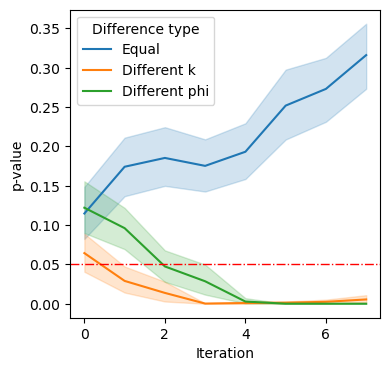

In [13]:
df = pd.DataFrame(pvals)
df.columns = list(range(df.shape[1] - 1)) + ["Difference type"]
df = df.melt(id_vars="Difference type",var_name="Iteration",value_name="p-value")
plt.figure(figsize=(4,4))
sns.lineplot(data=df, x='Iteration' , y='p-value', hue='Difference type')#.set_title(str(phi))
plt.axhline(0.05, linestyle='-.', linewidth=1, c='r')
name_str = get_plot_name(mname, n, k, m,"homogeneity_test_"+split_type.replace(" ", "_")+'_', params_str)
plt.savefig(name_str, bbox_inches='tight')
plt.show()

# Real data

## Auxiliary code

In [14]:
"""
Convert a list-of-paths description of a binary tree into a networkx DiGraph
and plot it.

Format:
- Each sublist is a root-to-leaf path.
- The first element is -1 (the root).
- After that, elements come in PAIRS: each pair (a, b) is a node labeled "a<b".
- Different paths may share a prefix of nodes (same pairs in the same order),
  which represents the same tree node.

Because it's a binary tree, at any internal node there are at most two children.
"""

import networkx as nx
import matplotlib.pyplot as plt


def build_tree(paths):
    """
    Build a DiGraph from the list-of-paths description.

    Returns
    -------
    G : nx.DiGraph
        Tree with string node IDs. Each node has a 'label' attribute like "a<b"
        (or "root" for the root).
    root_id : str
        ID of the root node.
    """
    G = nx.DiGraph()
    root_id = "root"
    G.add_node(root_id, label="root")

    for path in paths:
        assert path[0] == -1, "Every path must start with -1 (root)."
        body = path[1:]
        assert len(body) % 2 == 0, f"Path body must have even length, got {len(body)}: {path}"

        # Walk down the tree, reusing existing nodes when the prefix matches.
        current_id = root_id
        prefix = ()  # tuple of (a, b) pairs walked so far — uniquely identifies a node
        for i in range(0, len(body), 2):
            pair = (body[i], body[i + 1])
            prefix = prefix + (pair,)
            # Node ID encodes the full prefix so shared prefixes collapse to the same node.
            node_id = "|".join(f"{a},{b}" for a, b in prefix)
            label = f"{pair[0]}\u227A{pair[1]}"  # "a ≺ b"
            if node_id not in G:
                G.add_node(node_id, label=label)
                G.add_edge(current_id, node_id)
            current_id = node_id

    return G, root_id


def hierarchy_pos(G, root, width=1.0, vert_gap=0.2, xcenter=0.5):
    """
    Compute positions for a tree layout. Pure-Python, no graphviz needed.
    Places each subtree in a horizontal slice proportional to its leaf count.
    """
    # Count leaves under each node (for proportional width allocation).
    leaves = {}

    def count_leaves(n):
        children = list(G.successors(n))
        if not children:
            leaves[n] = 1
        else:
            leaves[n] = sum(count_leaves(c) for c in children)
        return leaves[n]

    count_leaves(root)

    pos = {}

    def place(n, left, right, depth):
        pos[n] = ((left + right) / 2, -depth * vert_gap)
        children = list(G.successors(n))
        if not children:
            return
        total = leaves[n]
        cursor = left
        for c in children:
            frac = leaves[c] / total
            c_right = cursor + frac * (right - left)
            place(c, cursor, c_right, depth + 1)
            cursor = c_right

    place(root, 0.0, width, 0)
    return pos


def plot_tree(paths, figsize=(16, 8), node_size=1400, font_size=9,
              title=None):
    G, root = build_tree(paths)
    pos = hierarchy_pos(G, root, width=2.0, vert_gap=0.25)
    labels = {n: d["label"] for n, d in G.nodes(data=True)}

    fig, ax = plt.subplots(figsize=figsize)
    nx.draw_networkx_edges(G, pos, ax=ax, arrows=False, edge_color="black")
    nx.draw_networkx_nodes(G, pos, node_color="white", edgecolors="black",
                           linewidths=1.2, node_size=node_size, ax=ax)
    nx.draw_networkx_labels(G, pos, labels=labels, font_size=font_size, ax=ax)

    if title:
        ax.set_title(title)
    ax.set_axis_off()
    plt.tight_layout()
    return G, fig




def plot_my_tree(paths, save_path=None, max_depth=None):    
    pathscopy = [path.copy() for path in paths]
    figsize=(19, 8)
    if max_depth is not None: #remove them form the list directly
        pathscopy = [path[:2*max_depth+1] for path in pathscopy]
        figsize = (5, 4)
    G, fig = plot_tree(pathscopy, figsize=figsize)
    # Sanity checks
    print(f"Nodes: {G.number_of_nodes()}, edges: {G.number_of_edges()}")
    # Binary-tree check: every internal node has at most 2 children.
    max_branching = max(G.out_degree(n) for n in G.nodes)
    print(f"Max children at any node: {max_branching}")
    if save_path is not None:
        plt.savefig(save_path, bbox_inches='tight')
    plt.show()
    

## Sushi dataset

In [15]:
import pandas as pd
def read_soc_rankings(path):
    rankings = []
    for line in open(path):
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        weight, ranking_str = line.split(":")
        ranking = [int(x) for x in ranking_str.split(",")]
        rankings.extend([ranking] * int(weight))  # repeat according to weight
    return np.array(rankings)
sample = read_soc_rankings("data/sushi-00014-00000001.soc")
m,n = sample.shape

No more pairs to split, stopping at iteration  17
No more pairs to split, stopping at iteration  29
No more pairs to split, stopping at iteration  19
No more pairs to split, stopping at iteration  26
No more pairs to split, stopping at iteration  20
No more pairs to split, stopping at iteration  26
No more pairs to split, stopping at iteration  22
No more pairs to split, stopping at iteration  21
No more pairs to split, stopping at iteration  23
No more pairs to split, stopping at iteration  29


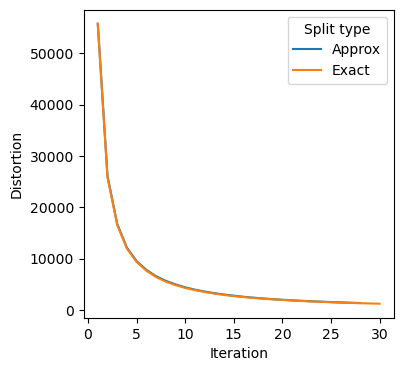

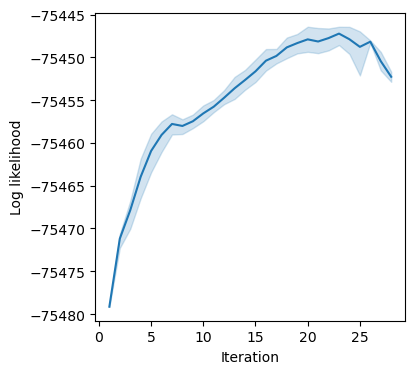

In [16]:
max_itera = 30
df = pd.DataFrame()
k = 2 #useless
centers = [np.random.permutation(range(n)) for _ in range(2)]# useless

split_types = ['Approx','Exact']#
for split_type in split_types: 
    if split_type == 'Approx': repes = 10
    else: repes = 1
    for repe in range(repes):
        dfinfo, dfnodes, dfedges, Ps, Ps_len, samples, split_pairs_sushi = coast(n,k, sample, centers, split_type, max_itera=max_itera, verbose=False)
        dfinfo['mname'] = 'sushi'
        dfinfo['m'] = m
        dfinfo['Split type'] = split_type
        #dfinfo['params'] = params if mname=='mm_ken' else 0
        df = pd.concat([df,dfinfo])
plt.figure(figsize=(4,4))
sns.lineplot(data=df, y='Distortion', x='Iteration',hue = 'Split type')
plt.savefig("img/COAST/sushi_distortion.pdf", bbox_inches='tight')
plt.show()
plt.figure(figsize=(4,4))
sns.lineplot(data=df[df['Split type']=='Approx'], y='Log likelihood', x='Iteration')
plt.savefig("img/COAST/sushi_likelihood.pdf", bbox_inches='tight')

Nodes: 59, edges: 58
Max children at any node: 2


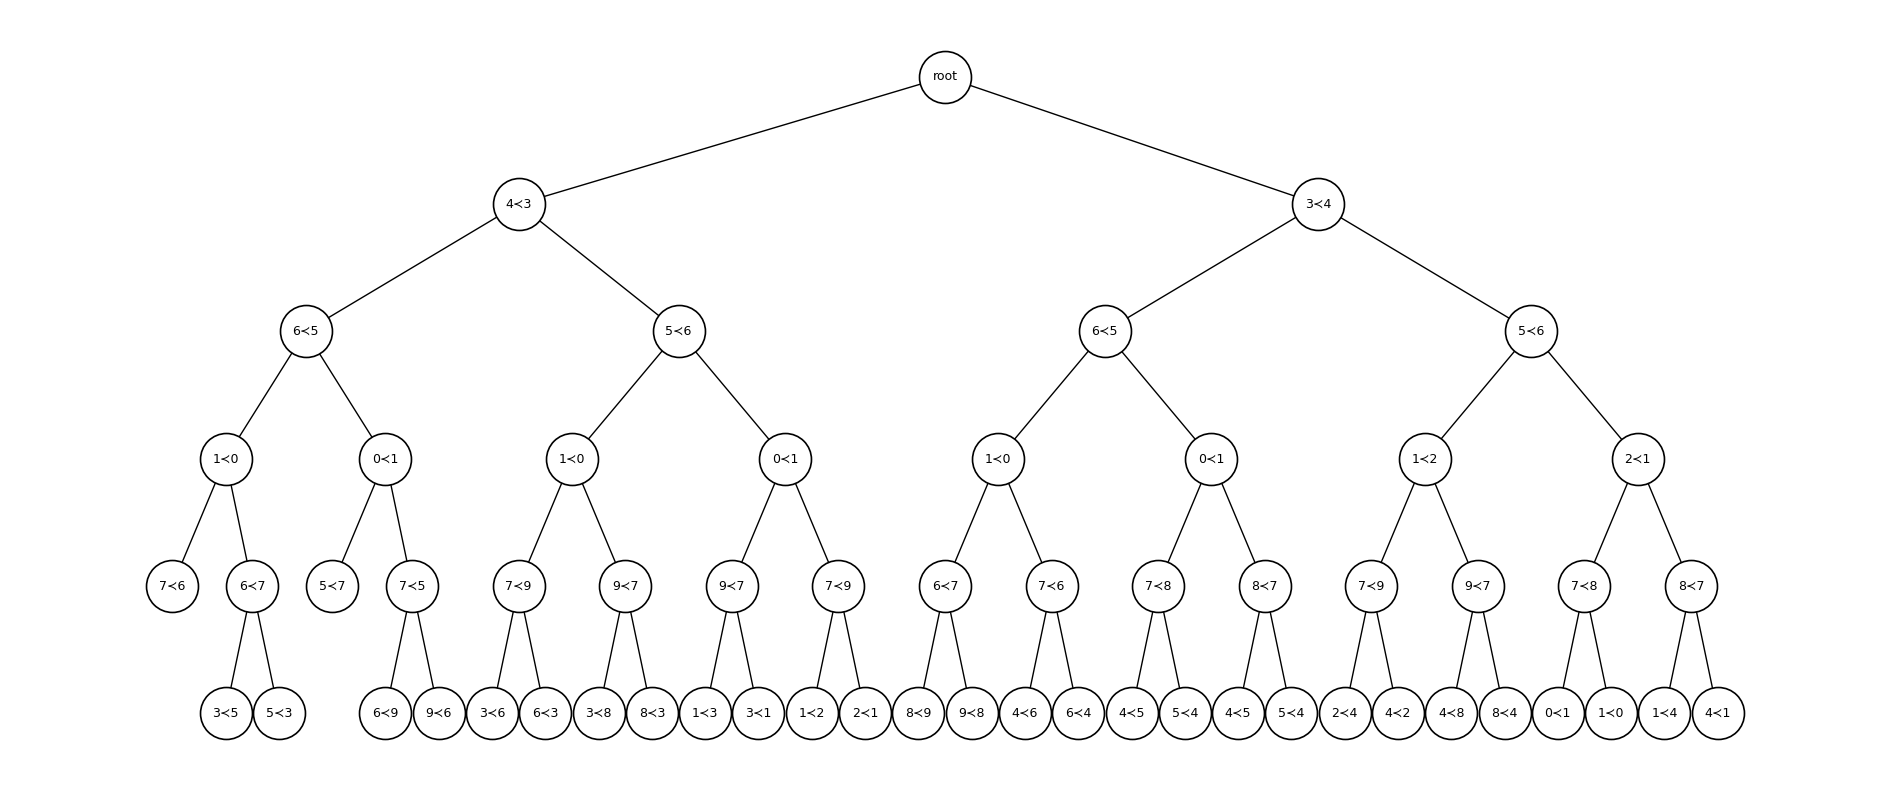

In [17]:
plot_my_tree(split_pairs_sushi, save_path="img/COAST/sushi_tree.pdf")

## LLM dataset, task level

Task level data from Colombo et al.

In [18]:

def ranking_aggregation(input_df, return_count=False):
    """
    :param input_df: input dataframe
    :param return_count: if True return borda count
    :return: rank obtained via borda count, borda count scores
    """
    rankings = []
    for index, columns in input_df.items():
        if index != 'Model':
            rankings.append(columns.argsort().argsort().values)

    df_ranking = np.argsort(np.argsort(sum(rankings)))
    if return_count:
        return df_ranking, sum(rankings)
    else:
        return df_ranking
    
def get_rankings(input_df):
    """
    :param input_df: input dataframe
    :return: rank obtained via borda count, borda count scores
    """
    rankings = []
    for index, columns in input_df.items():
        if index != 'Model':
            rankings.append(columns.argsort().argsort().values)
    return rankings



## LLM dataset, instance level
(2 level aggregation, TAC_08 dataset – instance-level rankings (no aggregation))


In [19]:
df_tac = pd.read_csv("data/TAC_08.csv")
metrics = [c for c in df_tac.columns if c not in ['System', 'Utterance']]
print("Metrics:", metrics)
print(f"Systems: {df_tac['System'].nunique()}  Utterances: {df_tac['Utterance'].nunique()}")
df_tac.head()

Metrics: ['H:pyr', 'H:resp', 'S3_pyr', 'S3_resp', 'ROUGE_WE_1', 'ROUGE_WE_2', 'JS_1', 'JS_2', 'ROUGE_L', 'ROUGE_1', 'ROUGE_2', 'BLEU', 'Chrfpp', 'BERTScore', 'MoverScore']
Systems: 48  Utterances: 62


,System,Utterance,H:pyr,H:resp,S3_pyr,S3_resp,ROUGE_WE_1,ROUGE_WE_2,JS_1,JS_2,ROUGE_L,ROUGE_1,ROUGE_2,BLEU,Chrfpp,BERTScore,MoverScore
0,0,M0,0.263,0.4,0.266698,0.407509,0.340102,0.166667,-0.499253,-0.627760,0.192893,0.345178,0.097436,11.887466,0.362953,0.586744,0.145967
1,0,M1,0.316,0.4,0.387789,0.483211,0.403553,0.238462,-0.454826,-0.596727,0.228426,0.416244,0.138462,23.964261,0.419907,0.619727,0.147530
2,0,M2,0.263,0.4,0.456964,0.544256,0.439086,0.264103,-0.428838,-0.566805,0.304569,0.456853,0.179487,36.476664,0.531733,0.635817,0.211053
3,0,M3,0.289,0.4,0.360855,0.468622,0.408629,0.246154,-0.483798,-0.593334,0.228426,0.401015,0.148718,30.983069,0.411381,0.586946,0.119991
4,0,M4,0.342,0.4,0.315286,0.433800,0.365482,0.205128,-0.489856,-0.611463,0.210660,0.375635,0.112821,11.968042,0.424539,0.588133,0.144689


In [20]:
def scores_by_utterances(df, metric):
    # shape (n_utterances, n_systems): row i = scores of all systems on utterance i
    pivot = df.pivot(index='Utterance', columns='System', values=metric)
    return pivot.index.tolist(), pivot.values

def rankings_by_utterances(df, metric):
    # Returns array (n_utterances, n_systems).
    # ranking[i, j] = rank of system j on utterance i (0 = worst, higher = better).
    utterances, scores = scores_by_utterances(df, metric)
    rankings = []
    for score in scores:
        r = np.argsort(np.argsort(score))
        rankings.append(r)
    return utterances, np.array(rankings)
# Build unaggregated rankings: one row per (metric, utterance)
records = []
for metric in metrics:
    utterances, rankings = rankings_by_utterances(df_tac, metric)
    for utt, ranking in zip(utterances, rankings):
        records.append({'metric': metric, 'utterance': utt, 'ranking': list(ranking)})

df_rankings = pd.DataFrame(records)
print(df_rankings.shape)  # (n_metrics * n_utterances, 3)
df_rankings

(930, 3)


,metric,utterance,ranking
0,H:pyr,M0,"[36, 22, 1, 23, 24, 47, 4, 12, 2, 33, 11, 16, ..."
1,H:pyr,M1,"[26, 38, 47, 46, 15, 14, 27, 28, 17, 44, 35, 2..."
2,H:pyr,M10,"[34, 41, 14, 32, 26, 9, 45, 15, 7, 33, 6, 11, ..."
3,H:pyr,M11,"[34, 38, 27, 28, 12, 20, 40, 15, 5, 45, 39, 6,..."
4,H:pyr,M12,"[35, 14, 30, 33, 8, 34, 21, 20, 4, 39, 43, 27,..."
...,...,...,...
925,MoverScore,M60,"[31, 23, 9, 37, 11, 15, 14, 16, 33, 18, 30, 22..."
926,MoverScore,M61,"[44, 35, 10, 31, 29, 37, 6, 14, 30, 7, 17, 4, ..."
927,MoverScore,M7,"[19, 25, 20, 33, 6, 3, 30, 36, 47, 29, 46, 18,..."
928,MoverScore,M8,"[29, 11, 22, 36, 0, 3, 39, 34, 46, 47, 41, 40,..."


Shape sample (5000, 10)
Exact time:  8.828085666999982
No more pairs to split, stopping at iteration  32
Approx time (repe 0):  4.063609366000037
No more pairs to split, stopping at iteration  20
Approx time (repe 1):  2.628816434999976
No more pairs to split, stopping at iteration  25
Approx time (repe 2):  3.1946848609999847
No more pairs to split, stopping at iteration  27
Approx time (repe 3):  3.3876280559999827
No more pairs to split, stopping at iteration  29
Approx time (repe 4):  3.638491731999977
No more pairs to split, stopping at iteration  19
Approx time (repe 5):  2.2631162110000105
No more pairs to split, stopping at iteration  25
Approx time (repe 6):  3.071493412000052
No more pairs to split, stopping at iteration  27
Approx time (repe 7):  3.3359134639999866
No more pairs to split, stopping at iteration  29
Approx time (repe 8):  3.6360739620000118
No more pairs to split, stopping at iteration  26
Approx time (repe 9):  3.382800852999992
Approx avg time: 3.26026283520

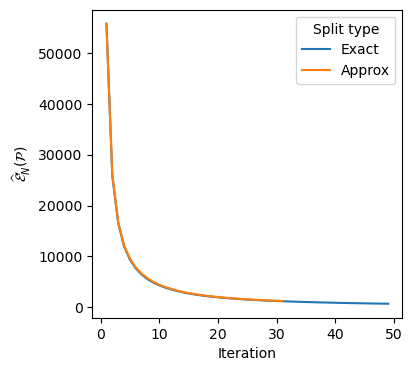

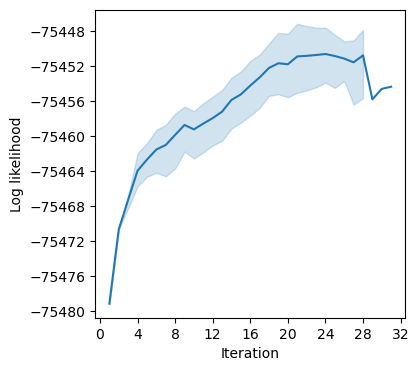

In [21]:
print("Shape sample", sample.shape)
m,n = sample.shape
# Run COAST with split_type='Approx' (same as Sushi experiment)
#k          = 2
max_itera  = 49
centers    = [np.random.permutation(range(n)) for _ in range(1)]# useless
repes      = 10
df   = pd.DataFrame()
# ===== EXACT =====
t0 = time.perf_counter()
dfinfo, dfnodes, dfedges, Ps, Ps_len, samples_out, split_pairs_exact = coast(
    n, None, sample, centers, 'Exact', max_itera=max_itera, verbose=False)
print("Exact time: ", time.perf_counter() - t0)
dfinfo['m'] = m
dfinfo['Split type'] = 'Exact'
df = pd.concat([df, dfinfo])
# ===== APPROX =====
times = []
for repe in range(repes):
    t0 = time.perf_counter()
    dfinfo, dfnodes, dfedges, Ps, Ps_len, samples_out, split_pairs = coast(
        n, None, sample, centers, 'Approx', max_itera=max_itera, verbose=False)
    dfinfo['m'] = m
    dfinfo['Split type'] = 'Approx'
    df = pd.concat([df, dfinfo])
    times.append(time.perf_counter() - t0)
    print(f"Approx time (repe {repe}): ", times[-1])

print("Approx avg time:", sum(times) / len(times))


plt.figure(figsize=(4, 4))
ax = sns.lineplot(data=df, y='Distortion', x='Iteration', hue='Split type')
ax.set_ylabel(r'$\widehat{\mathcal{E}}_N^\prime(\mathcal{P})$')
plt.savefig("img/COAST/TAC_08_distortion.pdf", bbox_inches='tight')
plt.show()

from matplotlib.ticker import MaxNLocator
plt.figure(figsize=(4, 4))
ax = sns.lineplot(data=df[df['Split type'] == 'Approx'],y='Log likelihood', x='Iteration')
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
plt.savefig("img/COAST/TAC_08_likelihood.pdf", bbox_inches='tight')


Nodes: 97, edges: 96
Max children at any node: 2


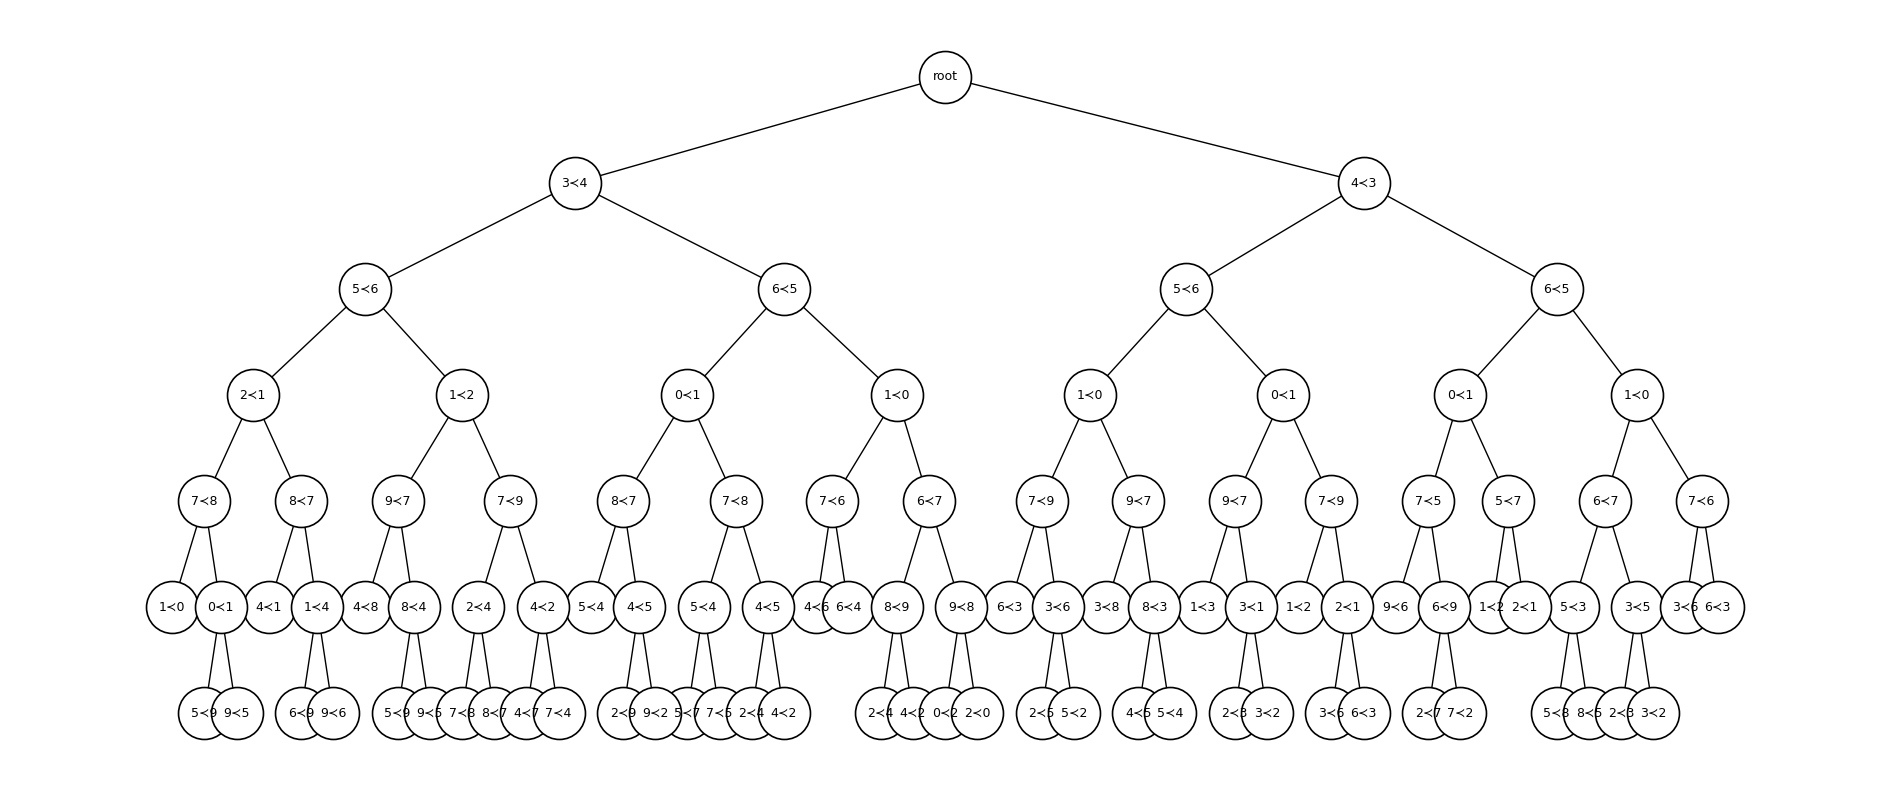

Nodes: 15, edges: 14
Max children at any node: 2


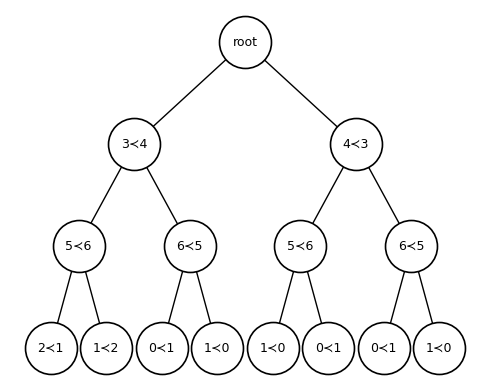

In [22]:
plot_my_tree(split_pairs_exact, save_path="img/COAST/TAC_08_tree.pdf" )
plot_my_tree(split_pairs_exact, save_path="img/COAST/TAC_08_tree_bounded.pdf" , max_depth=3)